In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

class_names = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

In [4]:
val_df = pd.read_csv("../data/processed/val.csv")

print("Validation images:", len(val_df))
print(val_df.head())

Validation images: 512
  split   class                                       image  \
0   Val  Glioma   ../data/raw/Val/Glioma/images/gg (10).jpg   
1   Val  Glioma  ../data/raw/Val/Glioma/images/gg (131).jpg   
2   Val  Glioma  ../data/raw/Val/Glioma/images/gg (132).jpg   
3   Val  Glioma  ../data/raw/Val/Glioma/images/gg (135).jpg   
4   Val  Glioma  ../data/raw/Val/Glioma/images/gg (136).jpg   

                                   annotation  label  
0   ../data/raw/Val/Glioma/labels/gg (10).txt      0  
1  ../data/raw/Val/Glioma/labels/gg (131).txt      0  
2  ../data/raw/Val/Glioma/labels/gg (132).txt      0  
3  ../data/raw/Val/Glioma/labels/gg (135).txt      0  
4  ../data/raw/Val/Glioma/labels/gg (136).txt      0  


In [5]:
val_df["image"] = val_df["image"].str.replace(
    "/raw/val/",
    "/raw/Val/",
    regex=False
)

missing = sum(
    not Path(p).exists()
    for p in val_df["image"]
)

print("Missing images:", missing)

Missing images: 0


In [6]:
def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, IMG_SIZE)
    image.set_shape((224, 224, 3))

    return image, label

In [8]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (
        val_df["image"].tolist(),
        val_df["label"].tolist()
    )
)

val_ds = val_ds.map(load_image)
val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

y_true = val_df["label"].to_numpy()

print("Validation dataset ready!")

Validation dataset ready!


In [9]:
mobile_path = Path("../models/finetuned_mobilenetv2.keras")
resnet_path = Path("../models/finetuned_resnet50v2.keras")

print("MobileNetV2:", mobile_path.exists())
print("ResNet50V2:", resnet_path.exists())

print("GPU:", tf.config.list_physical_devices("GPU"))

MobileNetV2: True
ResNet50V2: True
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
##Evaluate MobileNetV2

mobile_model = tf.keras.models.load_model(mobile_path)

mobile_predictions = mobile_model.predict(val_ds)

y_pred_mobile = np.argmax(
    mobile_predictions,
    axis=1
)

print("MobileNetV2 predictions ready!")

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step
MobileNetV2 predictions ready!


In [14]:
print("MobileNetV2 Results")

print(
    classification_report(
        y_true,
        y_pred_mobile,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

MobileNetV2 Results
              precision    recall  f1-score   support

      Glioma       0.96      0.77      0.86       136
  Meningioma       0.80      0.94      0.87       140
    No Tumor       1.00      0.95      0.97       100
   Pituitary       0.94      0.99      0.96       136

    accuracy                           0.91       512
   macro avg       0.93      0.91      0.91       512
weighted avg       0.92      0.91      0.91       512



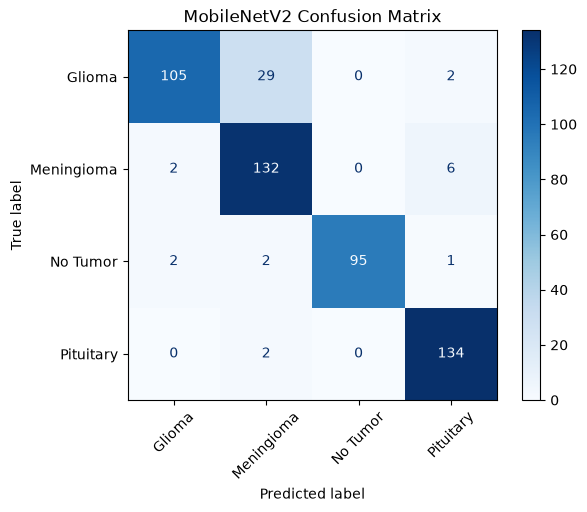

In [16]:
cm_mobile = confusion_matrix(
    y_true,
    y_pred_mobile,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    cm_mobile,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=45)

plt.title("MobileNetV2 Confusion Matrix")
plt.show()

In [17]:
##Evaluate ResNet50V2

import gc

del mobile_model

tf.keras.backend.clear_session()
gc.collect()

resnet_model = tf.keras.models.load_model(resnet_path)

resnet_predictions = resnet_model.predict(val_ds)

y_pred_resnet = np.argmax(
    resnet_predictions,
    axis=1
)

print("ResNet50V2 predictions ready!")

32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step
ResNet50V2 predictions ready!


In [18]:
print("ResNet50V2 Results")

print(
    classification_report(
        y_true,
        y_pred_resnet,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

ResNet50V2 Results
              precision    recall  f1-score   support

      Glioma       0.98      0.92      0.95       136
  Meningioma       0.89      0.96      0.92       140
    No Tumor       1.00      0.93      0.96       100
   Pituitary       0.96      0.99      0.98       136

    accuracy                           0.95       512
   macro avg       0.96      0.95      0.95       512
weighted avg       0.96      0.95      0.95       512



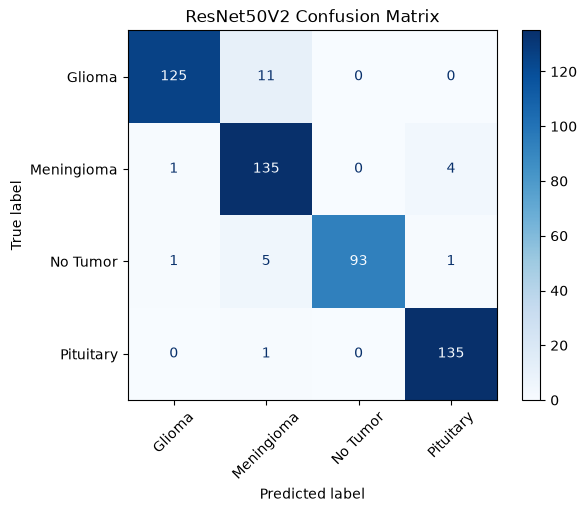

In [19]:
cm_resnet = confusion_matrix(
    y_true,
    y_pred_resnet,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    cm_resnet,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=45)

plt.title("ResNet50V2 Confusion Matrix")
plt.show()

In [20]:
comparison = pd.DataFrame({
    "Model": ["MobileNetV2", "ResNet50V2"],

    "Accuracy": [
        accuracy_score(y_true, y_pred_mobile),
        accuracy_score(y_true, y_pred_resnet)
    ],

    "F1-score": [
        f1_score(y_true, y_pred_mobile, average="macro"),
        f1_score(y_true, y_pred_resnet, average="macro")
    ]
})

print(comparison)

         Model  Accuracy  F1-score
0  MobileNetV2  0.910156  0.914412
1   ResNet50V2  0.953125  0.954305


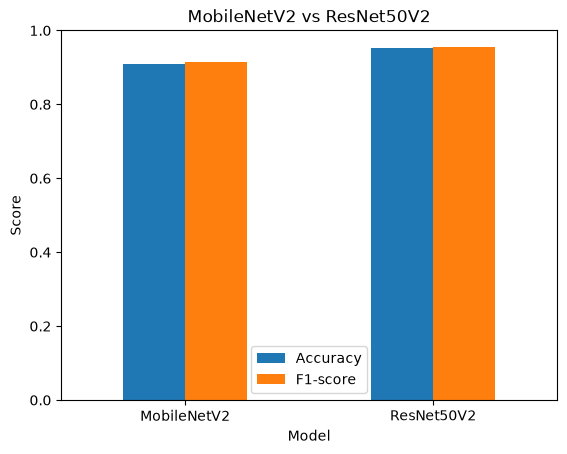

In [21]:
comparison.plot(
    x="Model",
    y=["Accuracy", "F1-score"],
    kind="bar",
    rot=0
)

plt.title("MobileNetV2 vs ResNet50V2")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.show()